<a href="https://colab.research.google.com/github/Vincent-L0/L02-hedonic-pricing/blob/main/notebook_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Vincent Lam, Tiffany Kim, Ashley Hughes

**Date:** 11/11/2026

In [11]:
# Your Phase 1 solution to the problem goes here.


df.shape:
(16814, 19) 

df.dtypes:
sale_date                      object
sale_price                      int64
house_square_feet               int64
attic_finished_square_feet      int64
basement_square_feet            int64
attached_garage_square_feet     int64
detached_garage_square_feet     int64
fireplaces                      int64
hvac_description               object
exterior                       object
interior                       object
stories                         int64
roof_cover                     object
year_built                      int64
bedrooms                        int64
bathrooms                       int64
waterfront_type                object
view_quality                   object
utility_sewer                  object
dtype: object 



,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,bathrooms
count,1.681400e+04,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000
mean,4.612332e+05,1879.941953,24.945878,167.852861,364.425122,38.298501,0.889021,1.558285,1980.469252,3.277983,2.317176
std,2.360833e+05,760.419008,102.066417,429.065832,286.454018,164.691471,0.596731,0.512055,33.339025,0.891240,0.827956
min,2.000000e+03,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1880.000000,0.000000,0.000000
25%,3.480000e+05,1320.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1959.000000,3.000000,2.000000
50%,4.165000e+05,1774.000000,0.000000,0.000000,420.000000,0.000000,1.000000,2.000000,1990.000000,3.000000,2.000000
75%,5.238065e+05,2352.000000,0.000000,0.000000,528.000000,0.000000,1.000000,2.000000,2006.000000,4.000000,3.000000
max,6.130000e+06,9510.000000,1212.000000,4000.000000,2816.000000,3664.000000,5.000000,3.000000,2021.000000,25.000000,8.000000


sale_date                          0
sale_price                         0
house_square_feet                  0
attic_finished_square_feet         0
basement_square_feet               0
attached_garage_square_feet        0
detached_garage_square_feet        0
fireplaces                         0
hvac_description                   7
exterior                           1
interior                           7
stories                            0
roof_cover                         8
year_built                         0
bedrooms                           0
bathrooms                          0
waterfront_type                16261
view_quality                   15895
utility_sewer                      0
dtype: int64 

hvac_description
Forced Air                10382
Electric Baseboard         2668
Heat Pump                  2084
Warm and Cool Air Zone     1268
Floor/Wall Furnace          174
Hot Water Baseboard         146
No Heat                      82
NaN                           7
Electric 

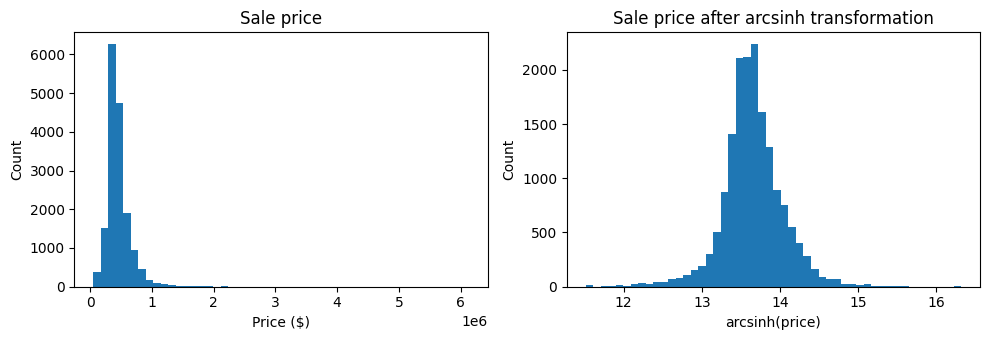

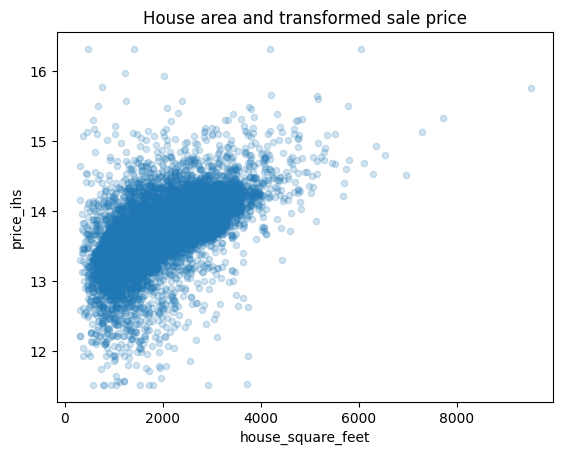

,price_ihs
price_ihs,1.000
house_square_feet,0.606
bathrooms,0.511
attached_garage_square_feet,0.391
fireplaces,0.384
year_built,0.334
bedrooms,0.312
stories,0.252
basement_square_feet,0.250
detached_garage_square_feet,0.027


In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score
from sklearn.linear_model import Lasso
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("pierce_county_house_sales.csv")

#1 Clean the data pierce_county_house_sales.csv and perform some EDA and visualization to get to know the data set.
# Look at initial characteristics
print("df.shape:")
print(df.shape, '\n')
print("df.dtypes:")
print(df.dtypes, '\n')
display(df.describe())
print(df.isnull().sum(), '\n')

# Look at the categorical variables
for var in ["hvac_description", "exterior", "interior", "roof_cover", "waterfront_type", "view_quality", "utility_sewer"]:
    print(df[var].value_counts(dropna=False), '\n')

# Clean the data
df = df.drop_duplicates()
df["waterfront_type"] = df["waterfront_type"].fillna("None")
df["view_quality"] = df["view_quality"].fillna("None")
df["hvac_description"] = df["hvac_description"].replace("Floor Wall Furnace", "Floor/Wall Furnace")
df = df.drop(columns=["interior", "utility_sewer", "sale_date"])
df = df.dropna(subset=["hvac_description", "exterior", "roof_cover"])

# transform price
df["price_ihs"] = np.arcsinh(df["sale_price"])

# Trim recording errors and non-market sales
df = df.loc[(df["price_ihs"] > 11.5) & (df["house_square_feet"] >= 300) & (df["bedrooms"] <= 10)].copy()
print(df.shape)

# Plot price before and after the arcsinh transformation
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
df["sale_price"].hist(bins=50, grid=False, ax=axes[0])
axes[0].set(title="Sale price", xlabel="Price ($)", ylabel="Count")
df["price_ihs"].hist(bins=50, grid=False, ax=axes[1])
axes[1].set(title="Sale price after arcsinh transformation", xlabel="arcsinh(price)", ylabel="Count")
plt.tight_layout()
plt.show()

# Plot house area against transformed price
df.plot.scatter(x="house_square_feet", y="price_ihs", alpha=0.2)
plt.title("House area and transformed sale price")
plt.show()

# Correlate numeric variables with transformed price
numeric_vars = ["house_square_feet", "attic_finished_square_feet", "basement_square_feet", "attached_garage_square_feet", "detached_garage_square_feet", "fireplaces", "stories", "bedrooms", "bathrooms", "year_built"]
correlations = df[numeric_vars + ["price_ihs"]].corr()
correlations["price_ihs"].sort_values(ascending=False).round(3)

In [13]:
#2 Transform your variables - particularly categorical ones - for use in your regression analysis.

categorical_vars = ["hvac_description", "exterior", "roof_cover", "waterfront_type", "view_quality"]
dummies = pd.get_dummies(df[categorical_vars], drop_first=True, dtype=int)
dummies.columns.tolist()

# Combine numeric variables and dummies into X, with transformed price as y
X = pd.concat([df[numeric_vars], dummies], axis=1)
y = df["price_ihs"]

In [14]:
#3 Implement an 80/20 train-test split. Put the test data aside.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=55
)

In [15]:
# 4 Build some simple linear models that include no transformations or interactions.
# Fit them, and determine their RMSE and R2 on the both the training and test sets. Which of your models does the best?
model_sets = {
    "House area only": ["house_square_feet"],
    "Numeric features": ["house_square_feet", "attic_finished_square_feet", "basement_square_feet", "attached_garage_square_feet", "detached_garage_square_feet", "fireplaces", "stories", "bedrooms", "bathrooms", "year_built"],
    "All features": X_train.columns.tolist(),
}

for name, features in model_sets.items():
    sk_fit = LinearRegression().fit(X_train[features], y_train)

    train_prediction = sk_fit.predict(X_train[features])
    test_prediction = sk_fit.predict(X_test[features])

    print(name)
    print("Training R-squared:", round(sk_fit.score(X_train[features], y_train), 3))
    print("Test R-squared:", round(sk_fit.score(X_test[features], y_test), 3))
    print("Training RMSE:", round(root_mean_squared_error(y_train, train_prediction), 3))
    print("Test RMSE:", round(root_mean_squared_error(y_test, test_prediction), 3))
    print("-------------------")
print("The model with all features does best, with the highest test R-squared (0.524) and the lowest test RMSE (0.275).")
print("Every increase in features helpedh. House area alone had a test R-squared of 0.370, but adding the other numeric features raised it to 0.464. Adding the categorical dummies on top raised it to 0.524.")
print("The training and test numbers are close for every model, so none are overfitting.")

House area only
Training R-squared: 0.367
Test R-squared: 0.37
Training RMSE: 0.322
Test RMSE: 0.316
-------------------
Numeric features
Training R-squared: 0.469
Test R-squared: 0.464
Training RMSE: 0.295
Test RMSE: 0.292
-------------------
All features
Training R-squared: 0.533
Test R-squared: 0.524
Training RMSE: 0.276
Test RMSE: 0.275
-------------------
The model with all features does best: it has the highest test R-squared (0.524) and the lowest test RMSE (0.275).
Each step up in features helped: house area alone had a test R-squared of 0.370, adding the other numeric features raised it to 0.464, and adding the categorical dummies raised it to 0.524.
The training and test numbers are close for every model, so none of them are overfitting.


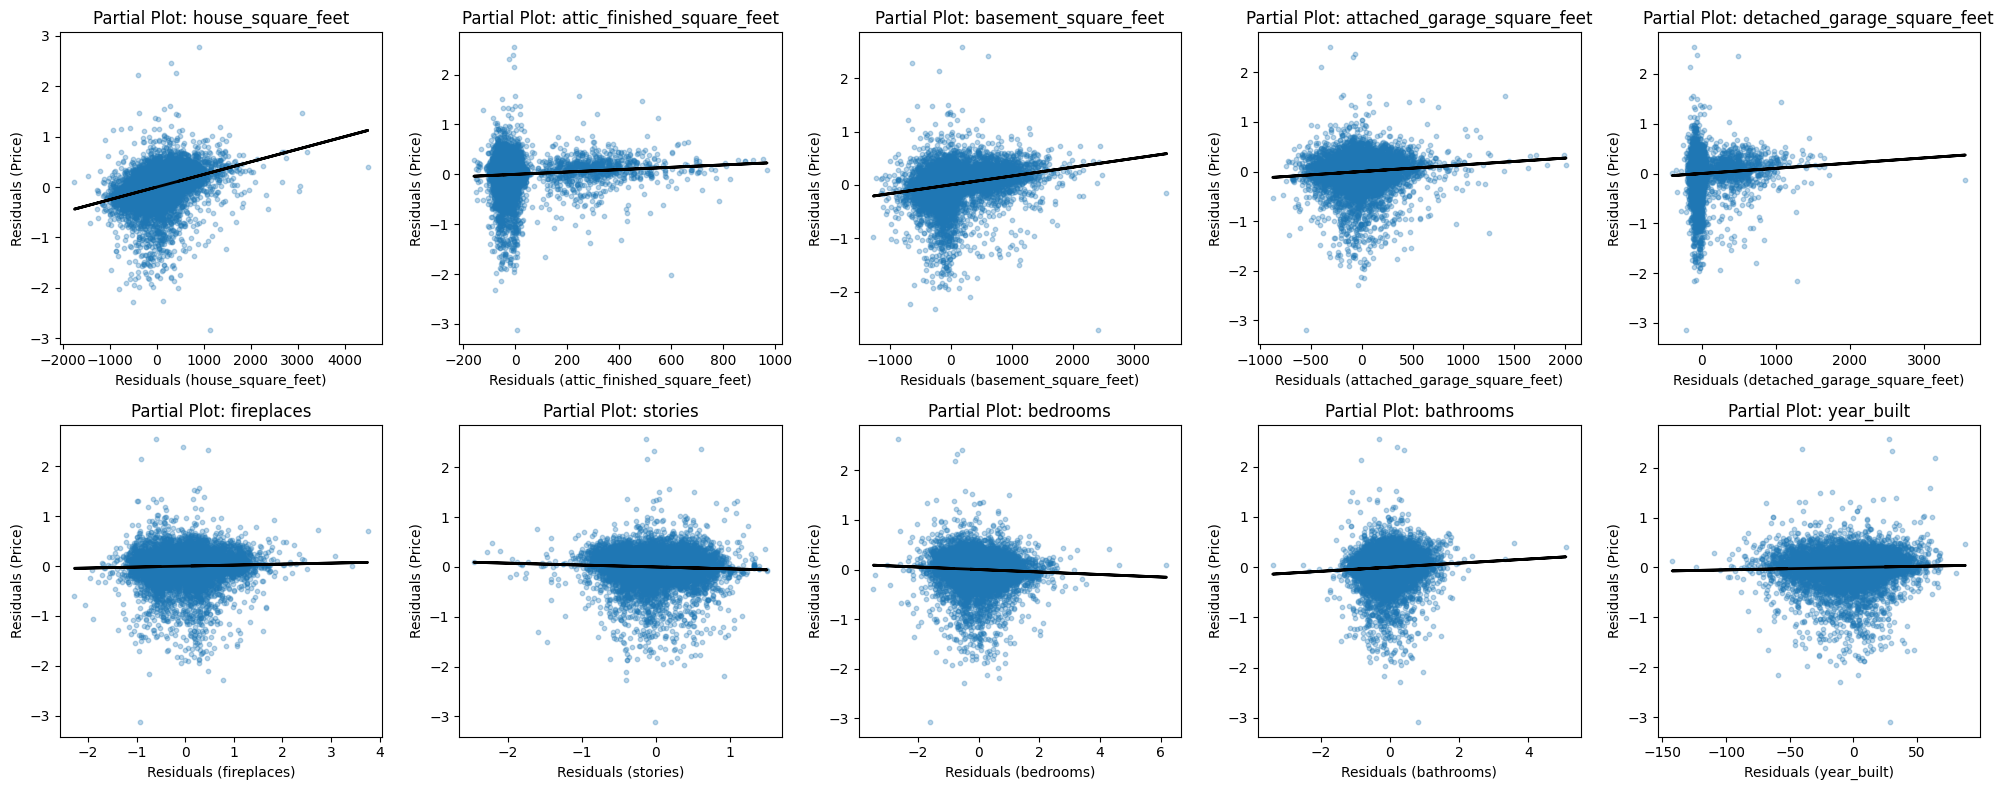

House area shows the clearest non-linearity: the points for the largest houses fall below the line, so each extra square foot adds less to price for big houses (diminishing returns).
Attic and detached garage area are zero for most houses, so their plots form a vertical stripe at zero with a thin tail, which a straight line does not describe well.
Bedrooms has a negative slope once the other features are held fixed, since more bedrooms in the same space means smaller rooms.
The other variables (basement, attached garage, fireplaces, stories, bathrooms, year built) look roughly linear, so the main non-linearity to address in the complex model is house size.


In [16]:
#5 Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
def slr(x, y):
    """Fit an intercept and one slope by ordinary least squares."""
    x_bar, y_bar = np.mean(x), np.mean(y)
    b1 = np.inner(x - x_bar, y - y_bar) / np.inner(x - x_bar, x - x_bar)
    b0 = y_bar - b1 * x_bar
    y_hat = b0 + b1 * x
    return {"b0": b0, "b1": b1, "y_hat": y_hat, "residuals": y - y_hat}

numeric_features = ["house_square_feet", "attic_finished_square_feet", "basement_square_feet", "attached_garage_square_feet", "detached_garage_square_feet", "fireplaces", "stories", "bedrooms", "bathrooms", "year_built"]

fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(20, 8))
axes = axes.flatten()

for i, feature in enumerate(numeric_features):
    others = X_train.drop(columns=feature)
    r_price = y_train - LinearRegression().fit(others, y_train).predict(others)
    r_feature = X_train[feature] - LinearRegression().fit(others, X_train[feature]).predict(others)
    partial_fit = slr(r_feature, r_price)

    ax = axes[i]
    ax.scatter(r_feature, r_price, alpha=0.3, s=10)
    ax.plot(r_feature, partial_fit["y_hat"], color="black", linewidth=2)
    ax.set_title(f"Partial Plot: {feature}")
    ax.set_xlabel(f"Residuals ({feature})")
    ax.set_ylabel("Residuals (Price)")

plt.tight_layout()
plt.show()

print("House area is the main non-linearity: for the biggest houses, each extra square foot adds less to the price.")
print("Attic and detached garage area are zero for most houses, so a straight line doesn't fit them well.")
print("Bedrooms has a negative effect once size is held fixed, because more bedrooms in the same space means smaller rooms.")
print("The other variables look roughly linear, so house size is the main thing to fix in the complex model.")

In [21]:
#6 Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value.
# Determine its RMSE and R2 on the training and test sets. How does the more complex model your build compare to the simpler ones?

# Log-transform house size
X_train_log = X_train.copy()
X_test_log = X_test.copy()
X_train_log["house_square_feet"] = np.log(X_train_log["house_square_feet"])
X_test_log["house_square_feet"] = np.log(X_test_log["house_square_feet"])

# Add squares and interactions of the numeric features
numeric_features = ["house_square_feet", "attic_finished_square_feet", "basement_square_feet", "attached_garage_square_feet", "detached_garage_square_feet", "fireplaces", "stories", "bedrooms", "bathrooms", "year_built"]
expander = make_pipeline(
    MinMaxScaler(feature_range=(-1, 1)),
    PolynomialFeatures(degree=2, include_bias=False)
)
poly_train = pd.DataFrame(expander.fit_transform(X_train_log[numeric_features]), columns=expander.get_feature_names_out(), index=X_train_log.index)
poly_test = pd.DataFrame(expander.transform(X_test_log[numeric_features]), columns=expander.get_feature_names_out(), index=X_test_log.index)

# Combine with the dummies and fit the complex model
X_train_c = pd.concat([poly_train, X_train_log.drop(columns=numeric_features)], axis=1)
X_test_c = pd.concat([poly_test, X_test_log.drop(columns=numeric_features)], axis=1)
c_model = LinearRegression().fit(X_train_c, y_train)

print("Complex Training R-squared:", round(c_model.score(X_train_c, y_train), 3))
print("Complex Test R-squared:", round(c_model.score(X_test_c, y_test), 3))
print("Complex Training RMSE:", round(root_mean_squared_error(y_train, c_model.predict(X_train_c)), 3))
print("Complex Test RMSE:", round(root_mean_squared_error(y_test, c_model.predict(X_test_c)), 3))
print("")
print("We log-transformed house area because bigger houses add less value per square foot. We also added squares so effects can curve, and interactions so one feature can change another's effect (like a bathroom adding more value in a bigger house).")
print("The complex model beats every simple model on the test set: test R-squared 0.543 vs 0.524, and test RMSE 0.269 vs 0.275.")
print("Its training and test scores are close (0.554 vs 0.543), so it isn't overfitting.")

Complex Training R-squared: 0.554
Complex Test R-squared: 0.543
Complex Training RMSE: 0.27
Complex Test RMSE: 0.269

We log-transformed house area because the partial plot showed diminishing returns to size. We also added squares of the numeric features so their effects can curve, and pairwise interactions so one feature's effect can depend on another (for example, a bathroom adding more value in a bigger house, or the effect of age depending on size). The categorical dummies were kept as they are.
The complex model does better than every simple model on the test set: test R-squared 0.543 vs 0.524 for the best simple model, and test RMSE 0.269 vs 0.275.
Its training and test scores stay close (0.554 vs 0.543), so the extra terms captured real patterns instead of overfitting.


In [18]:
# 7 Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
print("After cleaning (removing duplicates, filling missing waterfront and view values, dropping near-constant columns, and trimming non-market sales), we transformed sale price with arcsinh, encoded the categorical variables as dummies, and used an 80/20 train-test split.")
print("For the simple model with only house area, our training R^2 was 0.367, our test R^2 was 0.370, our training RMSE was 0.322, and our test RMSE was 0.316.")
print("For the simple model with all features and no transformations, our training R^2 was 0.533, our test R^2 was 0.524, our training RMSE was 0.276, and our test RMSE was 0.275.")
print("For the complex model with a log transformation of house area and squares and interactions of the numeric features, our training R^2 was 0.554, our test R^2 was 0.543, our training RMSE was 0.270, and our test RMSE was 0.269.")

print("RMSE is on the arcsinh price scale, so an RMSE of about 0.27 means our predictions are typically off by roughly 27% of the sale price.")
print("The house area model underfits: it is too simple to capture what drives price, so its training and test errors are both high. Adding the other numeric features and the categorical dummies lowered the error on both sets.")
print("The all-features simple model explains roughly 52% of the variation in price on unseen data. There is a relatively small gap between the training and test metrics, which indicates that the model is not overfitting.")
print("The complex model did better than every simple model on the test set, and its training and test metrics stayed close, so the extra terms captured real patterns instead of noise.")
print("We utilized transformations because sale_price and house_square_feet were both heavily right skewed, and the partial correlation plots showed diminishing returns to house size, so we transformed them to prevent outliers from dominating the regression.")
print("We learned that test metrics are very important when determining if a model is overfitting. Training error always goes down as we add features, so only the test set shows whether a model is actually learning or just memorizing the training data.")
print("We also learned that the goal of model selection is finding a good in-between. We needed a model that was complex enough to capture the patterns, like diminishing returns to house size, but we limited the squares and interactions to the numeric features instead of every column to avoid overfitting.")

After cleaning (removing duplicates, filling missing waterfront and view values, dropping near-constant columns, and trimming non-market sales), we transformed sale price with arcsinh, encoded the categorical variables as dummies, and used an 80/20 train-test split.
For the simple model with only house area, our training R^2 was 0.367, our test R^2 was 0.370, our training RMSE was 0.322, and our test RMSE was 0.316.
For the simple model with all features and no transformations, our training R^2 was 0.533, our test R^2 was 0.524, our training RMSE was 0.276, and our test RMSE was 0.275.
For the complex model with a log transformation of house area and squares and interactions of the numeric features, our training R^2 was 0.554, our test R^2 was 0.543, our training RMSE was 0.270, and our test RMSE was 0.269.
RMSE is on the arcsinh price scale, so an RMSE of about 0.27 means our predictions are typically off by roughly 27% of the sale price.
The house area model underfits: it is too simp

In [19]:
#8 Use the sklearn.linear_model.Lasso to regularize your model and select the most predictive features.
# Which does it select? What are the RMSE and R2?

# Standardize the complex-model features then fit the lasso
model = make_pipeline(StandardScaler(), Lasso(max_iter=20000))

# Choose the penalty by 5-fold cross-validation on the training data
cv = KFold(n_splits=5, shuffle=True, random_state=3001)
search = GridSearchCV(model, {"lasso__alpha": [0.0003, 0.001, 0.003, 0.01]}, cv=cv, scoring="neg_root_mean_squared_error", error_score="raise")
search.fit(X_train_c, y_train);
print("Selected alpha:", search.best_params_["lasso__alpha"])
print("Validation RMSE:", round(-search.best_score_, 3))

# Training and test R-squared and RMSE of the refitted model
best_model = search.best_estimator_
print("Lasso Training R-squared:", round(best_model.score(X_train_c, y_train), 3))
print("Lasso Test R-squared:", round(best_model.score(X_test_c, y_test), 3))
print("Lasso Training RMSE:", round(root_mean_squared_error(y_train, best_model.predict(X_train_c)), 3))
print("Lasso Test RMSE:", round(root_mean_squared_error(y_test, best_model.predict(X_test_c)), 3))

# Features with nonzero coefficients
lasso = best_model.named_steps["lasso"]
coefs = pd.Series(lasso.coef_, index=X_train_c.columns)
selected = coefs[coefs != 0]
print("Nonzero coefficients:", len(selected), "of", len(coefs))
print(selected.reindex(selected.abs().sort_values(ascending=False).index).round(3))
print("")
# Answer
print("Cross-validation picked alpha = 0.001. The lasso's test R-squared is 0.540 and test RMSE is 0.270.")
print("It keeps 66 of the 104 features. The most important are house area, waterfront (salt water and lake), and the squares and interactions involving house area and year built.")
print("It does almost as well as the complex model (0.540 vs 0.543) with fewer features.")

Selected alpha: 0.001
Validation RMSE: 0.275
Lasso Training R-squared: 0.549
Lasso Test R-squared: 0.54
Lasso Training RMSE: 0.272
Lasso Test RMSE: 0.27
Nonzero coefficients: 66 of 104
house_square_feet                  0.148
waterfront_type_WF Salt            0.072
basement_square_feet^2            -0.066
waterfront_type_WF Lake            0.049
bathrooms year_built              -0.047
                                   ...  
attic_finished_square_feet^2      -0.001
stories^2                         -0.001
fireplaces stories                 0.000
roof_cover_Preformed Metal         0.000
waterfront_type_WF Stream/Creek   -0.000
Length: 66, dtype: float64
Cross-validation selected alpha = 0.001. The lasso has test R-squared 0.540 and test RMSE 0.270 (training 0.549 and 0.272).
It keeps 66 of the 104 features. The most predictive are log house area, salt-water and lake waterfront, the squares of house area, basement area and year built, and interactions of year built with bathrooms, stor

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [20]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]